# This notebook helps to read the .cnt file and looks at what are trial annotations and response annotations

In [1]:
import mne
import matplotlib.pyplot as plt

In [2]:
import numpy as np
import pandas as pd

In [3]:
# Read the csv file for beh data
behdata_df = pd.read_csv('../../beh_data/behfile.csv')

In [4]:
# Read the .cnt file
cnt_file = '/Users/sri/Downloads/Dataset_1/122.cnt'
raw = mne.io.read_raw_cnt(cnt_file, preload=True)

Reading 0 ... 545419  =      0.000 ...  1090.838 secs...


/var/folders/n2/vs914nyj7g5__mmfqkwqf9s80000gn/T/ipykernel_5002/1595169649.py:3: RuntimeWarning:   Could not parse meas date from the header. Setting to None.
  raw = mne.io.read_raw_cnt(cnt_file, preload=True)
/var/folders/n2/vs914nyj7g5__mmfqkwqf9s80000gn/T/ipykernel_5002/1595169649.py:3: RuntimeWarning: Could not define the number of bytes automatically. Defaulting to 2.
  raw = mne.io.read_raw_cnt(cnt_file, preload=True)


In [5]:
# Print summary info about the file
print(raw)
print(raw.info)  # Prints metadata

<RawCNT | 122.cnt, 64 x 545420 (1090.8 s), ~266.4 MiB, data loaded>
<Info | 9 non-empty values
 bads: []
 ch_names: AFz, Fz, FCz, CPz, Pz, POz, Oz, IZ, AF3, AF7, F1, F3, F5, F7, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | id: 0, sex: 0 (FIFFV_SUBJ_SEX_UNKNOWN), first_name: , last_name: >
>


In [6]:
events, event_id = mne.events_from_annotations(raw)
print("Events shape:", events.shape)
print("Event IDs:", event_id)

Used Annotations descriptions: [np.str_('1'), np.str_('2'), np.str_('KeyPad Response 1'), np.str_('KeyPad Response 8')]
Events shape: (177, 3)
Event IDs: {np.str_('1'): 1, np.str_('2'): 2, np.str_('KeyPad Response 1'): 3, np.str_('KeyPad Response 8'): 4}


In [7]:
unique_values, counts = np.unique(events[:, 2], return_counts=True)
for value, count in zip(unique_values, counts):
    print(f"event# {value} occurs:  {count} times")

event# 1 occurs:  54 times
event# 2 occurs:  55 times
event# 3 occurs:  37 times
event# 4 occurs:  31 times


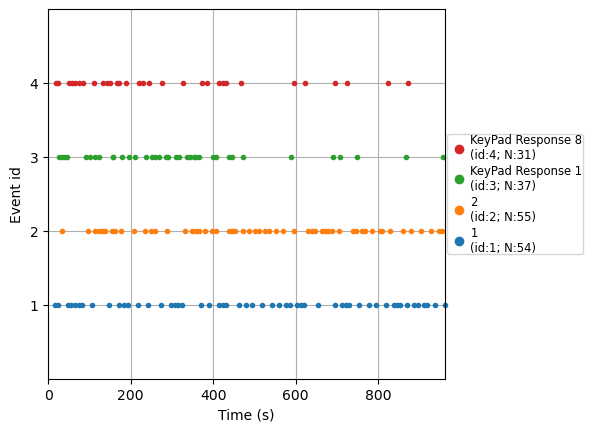

In [8]:
tempval = mne.viz.plot_events(events=events, event_id=event_id, sfreq=raw.info["sfreq"])

In [9]:
# raw.plot(
#     events=events,
#     start=0,
#     duration=10,
#     color="gray",
#     event_color={1: "r", 2: "g", 3: "b", 4: "m"},
# )

In [10]:
row_events = [
    "1",
    "2"]

In [11]:
metadata_tmin = row_events
metadata_tmax = ["KeyPad Response 1", "KeyPad Response 8"]

metadata, events, event_id = mne.epochs.make_metadata(
    events=events,
    event_id=event_id,
    tmin=metadata_tmin,
    tmax=metadata_tmax,
    sfreq=raw.info["sfreq"],
    row_events=row_events,
)

In [12]:
metadata['trial'] = range(1, len(metadata) + 1)

In [13]:
def extract_response(row):
    if pd.notna(row['KeyPad Response 1']):
        return pd.Series([1, row['KeyPad Response 1']])
    elif pd.notna(row['KeyPad Response 8']):
        return pd.Series([8, row['KeyPad Response 8']])
    else:
        return pd.Series([None, None])

metadata[['resp', 'rt']] = metadata.apply(extract_response, axis=1)
metadata = metadata[['trial', 'event_name', 'resp', 'rt']]
metadata = metadata.reset_index(drop=True)


In [14]:
metadata.head(25)

,trial,event_name,resp,rt
0,1,1,8.0,1.984
1,2,1,1.0,2.556
2,3,2,1.0,1.822
3,4,1,8.0,3.734
4,5,1,8.0,2.306
5,6,1,8.0,1.802
6,7,1,8.0,1.484
7,8,1,8.0,1.822
8,9,2,1.0,4.280
9,10,1,8.0,3.786


In [15]:
behdata_df.head(25)

,Trlnumber,ReactionTime,OverallRT,TrialTime,HoriGold
0,1,1.984,18.490,16.506,Ripples
1,2,2.556,27.314,24.758,Ripples
2,3,1.822,34.298,32.476,nc
3,4,3.734,51.346,47.612,Alert
4,5,2.306,57.016,54.710,nc
5,6,1.802,66.102,64.300,Alert
6,7,1.484,75.104,73.620,Alert
7,8,1.822,84.698,82.876,Alert
8,9,4.280,101.538,97.258,Alert
9,10,3.786,110.182,106.396,Alert


In [16]:
#you can compare and see that metadata and behdata in terms of the rt are the same..